##IMPORTAR LIBRERIAS

In [ ]:
pip install magpylib

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import magpylib as magpy
import matplotlib.patches as patches

##DEFINICION DE FUNCIONES

In [ ]:
class iman:
    def __init__(self, posicion, radio, altura, direccion, intensidad):
        self.posicion = posicion  # (x, y, z)
        self.radio = radio
        self.altura = altura
        self.direccion = direccion
        self.intensidad = intensidad

    def magpylib(self):
        return magpy.magnet.Cylinder(
            magnetization=(0, 0, self.direccion * self.intensidad),
            dimension=(2 * self.radio, self.altura),
            position=self.posicion
        )

#FUNCIÓN PARA PLOTEAR EL CAMPO EN UN PLANO

#EL FLUJO ES:
#CREAR LA GRILLA DONDE QUEREMOS EL CAMPO
#OBTENER EL CAMPO
#PLOTEAR

def plot_plano(coleccion, imanes, xlim, zlim, y_plano = 0 , resolucion = 100, densidad = 15, plot_type = "fieldline", zoom = False):

  #CREAMOS LA MATRIZ O GRID

  x = np.linspace(*xlim, resolucion)
  z = np.linspace(*zlim, resolucion)
  X, Z = np.meshgrid(x, z)
  Y = np.full_like(X, y_plano)
  posiciones = np.stack([X, Y, Z], axis=-1).reshape(-1, 3)

  #CALCULA EL CAMPO MAGNETICO, DIFERENCIA LAS COMPONENTES Y CALCULA LA INTENSIDAD.

  B = coleccion.getB(posiciones).reshape(X.shape + (3,))
  BX = B[:, :, 0]
  BZ = B[:, :, 2]
  magnitude = np.linalg.norm([BX, BZ], axis=0)

 #PLOTEO
  plt.style.use('dark_background')
  fig, ax = plt.subplots(figsize=(10, 6))

  if plot_type == 'fieldline':
    stream = ax.streamplot(
            X, Z, BX, BZ,
            color=np.log(magnitude + 1e-12),  # Avoid log(0)
            cmap='viridis',
            density=densidad,
            linewidth=1.0
    )

    plt.colorbar(stream.lines, label='Log( Field strength [T] )')

  elif plot_type == 'field_direction':
      qiver = ax.quiver(
            X, Z, BX/magnitude*0.04, BZ/magnitude*0.04,
            np.log(magnitude + 1e-12),  # Avoid log(0)
            cmap='viridis',
            scale=2,  # adjust to get good arrow length
            width=0.002,  # arrow width
            pivot='middle'
        )
      if zoom == True:
        ax.set_xlim(xlim[0], xlim[1])
        ax.set_ylim(zlim[0], zlim[1])

      plt.colorbar(qiver, label='Log( Field strength [T] )')

  else:
    raise ValueError('Unknown visualiztaion type')


  ax.set_facecolor((0.1, 0.1, 0.1))
  ax.set_xlabel("X [mm]")
  ax.set_ylabel("Z [mm]")
  ax.set_xlim(xlim)
  ax.set_ylim(zlim)
  ax.set_title("Magnetic Field Lines in XZ Plane")
  ax.grid(False)
  fig.set_facecolor((0.1, 0.1, 0.1))

#DIBUJA LOS IMANES

  for m in imanes:
      # Magpylib Cylinder objects store position as 'position' and dimensions as 'dimension = (diameter, height)'
      x0 = m.position[0] - m.dimension[0] / 2 # x-coordinate of the bottom-left corner
      z0 = m.position[2] - m.dimension[1] / 2 # z-coordinate of the bottom-left corner
      # Draw semi-transparent white filled rectangle
      face_rect = patches.Rectangle(
          (x0, z0),
          width=m.dimension[0],
          height=m.dimension[1],
          facecolor='white',
          edgecolor='none',
          alpha=0.3
        )
      ax.add_patch(face_rect)

  plt.tight_layout()
  plt.show()

#calculo de r^2

def calcular_r2(x, angulo, x_range=None):
    if x_range is not None:
        mask = (x >= x_range[0]) & (x <= x_range[1])
        x = x[mask]
        angulo = angulo[mask]

    coef = np.polyfit(x, angulo, 1)
    ajuste = np.polyval(coef, x)
    ss_res = np.sum((angulo - ajuste) ** 2)
    ss_tot = np.sum((angulo - np.mean(angulo)) ** 2)
    r2 = 1 - ss_res / ss_tot
    return r2


#FUNCIÓN PARA PLOTEAR EL ÁNGULO DEL CAMPO EN FUNCIÓN DE X
#EL FLUJO ES:
#EVALUAR EL CAMPO A LO LARGO DE UNA LÍNEA EN X, PARA CADA ALTURA Z PEDIDA
#CALCULAR EL ÁNGULO CON ARCTAN2(BZ, BX)
#CALCULAR EL R² DE LA LINEALIDAD PARA CADA Z Y MOSTRARLO EN LA LEYENDA
#PLOTEAR TODAS LAS ALTURAS SUPERPUESTAS

def plot_field_angle(coleccion, xlim, alturas_z, y_plano=0, resolucion=200, x_range_r2=None, cmap='viridis', ax=None):

    x = np.linspace(*xlim, resolucion)

    standalone = ax is None
    if standalone:
        plt.style.use('dark_background')
        fig, ax = plt.subplots(figsize=(10, 6))

    colores = plt.get_cmap(cmap)(np.linspace(0, 1, len(alturas_z)))

    metricas_por_z = {}

    for z, color in zip(alturas_z, colores):
        Y = np.full_like(x, y_plano)
        Z = np.full_like(x, z)
        posiciones = np.stack([x, Y, Z], axis=-1)

        B = coleccion.getB(posiciones)
        BX = B[:, 0]
        BZ = B[:, 2]

        angulo = np.degrees(np.arctan2(BZ, BX))
        r2 = calcular_r2(x, angulo, x_range=x_range_r2)
        amplitud = np.mean(np.sqrt(BX**2 + BZ**2)) * 1000

        metricas_por_z[z] = {"r2": r2, "amplitud_mT": amplitud}

        ax.plot(x, angulo, color=color, label=f"Z={z}mm (R²={r2:.4f}, |B|={amplitud:.2f}mT)")

    if x_range_r2 is not None:
        ax.axvspan(x_range_r2[0], x_range_r2[1], color='white', alpha=0.05)

    ax.set_facecolor((0.1, 0.1, 0.1))
    ax.set_xlabel("X [mm]")
    ax.set_ylabel("Field angle [degrees]")
    ax.set_title(f"Magnetic Field Rotation Along Line (y={y_plano}mm)")
    ax.legend()
    ax.grid(alpha=0.2)

    if standalone:
        ax.figure.set_facecolor((0.1, 0.1, 0.1))
        plt.tight_layout()
        plt.show()

    return metricas_por_z

#FUNCIÓN PARA PLOTEAR TODOS LOS LISSAJOUS DE UN y_plano EN UNA MISMA FIGURA
#EL FLUJO ES:
#EVALUAR BX, BZ PARA CADA ALTURA Z
#CALCULAR LOS LÍMITES GLOBALES (MISMA ESCALA PARA TODOS LOS SUBPLOTS)
#DIBUJAR CADA Z EN SU PROPIO SUBPLOT, COMPARTIENDO EJES

def plot_lissajous_grid(coleccion, xlim, alturas_z, y_plano=0, resolucion=200):

    x = np.linspace(*xlim, resolucion)
    datos = {}

    bx_all, bz_all = [], []
    for z in alturas_z:
        Y = np.full_like(x, y_plano)
        Z = np.full_like(x, z)
        posiciones = np.stack([x, Y, Z], axis=-1)
        B = coleccion.getB(posiciones)
        BX, BZ = B[:, 0], B[:, 2]
        datos[z] = (BX, BZ)
        bx_all.append(BX)
        bz_all.append(BZ)

    # límites comunes a todos los subplots, para poder comparar escala real
    bx_all = np.concatenate(bx_all)
    bz_all = np.concatenate(bz_all)
    margen = 0.05 * max(np.ptp(bx_all), np.ptp(bz_all))
    xlims = (bx_all.min() - margen, bx_all.max() + margen)
    ylims = (bz_all.min() - margen, bz_all.max() + margen)

    plt.style.use('dark_background')
    n = len(alturas_z)
    fig, axs = plt.subplots(1, n, figsize=(4 * n, 4), sharex=True, sharey=True)
    if n == 1:
        axs = [axs]

    sc = None
    for ax, z in zip(axs, alturas_z):
        BX, BZ = datos[z]
        sc = ax.scatter(BX, BZ, c=x, cmap='viridis', s=8)
        ax.plot(BX, BZ, color='white', alpha=0.3, linewidth=0.5)
        ax.set_facecolor((0.1, 0.1, 0.1))
        ax.set_xlim(xlims)
        ax.set_ylim(ylims)
        ax.set_xlabel("Bx [T]")
        ax.set_title(f"Z={z}mm")
        ax.set_aspect('equal')
        ax.grid(alpha=0.2)

    axs[0].set_ylabel("Bz [T]")
    fig.suptitle(f"Lissajous — escala común (y={y_plano:.2f}mm)")
    fig.colorbar(sc, ax=axs, label='X [mm]', shrink=0.8)
    fig.set_facecolor((0.1, 0.1, 0.1))
    plt.show()


def calcular_metricas_linealidad(x, angulo, x_range=None):
    if x_range is not None:
        mask = (x >= x_range[0]) & (x <= x_range[1])
        x, angulo = x[mask], angulo[mask]

    coef = np.polyfit(x, angulo, 1)
    ajuste = np.polyval(coef, x)
    residuos = angulo - ajuste

    r2 = 1 - np.sum(residuos**2) / np.sum((angulo - np.mean(angulo))**2)
    error_max = np.max(np.abs(residuos))      # grados, worst-case (INL)
    error_rms = np.sqrt(np.mean(residuos**2)) # grados, promedio

    return {"r2": r2, "error_max_deg": error_max, "error_rms_deg": error_rms}

#FUNCIÓN PARA BARRER DISTINTOS VALORES DE Y_PLANO
#EL FLUJO ES:
#GENERAR LOS VALORES DE Y_PLANO A EVALUAR
#PARA CADA UNO, PLOTEAR FIELD ANGLE (CON R²) Y LA GRILLA DE LISSAJOUS EN ESCALA COMÚN
#GUARDAR LOS R² DE TODOS LOS Y_PLANO PARA COMPARAR AL FINAL

def barrer_y_plano(coleccion, imanes, xlim, zlim, alturas_z, altura_lissajous,
                    n_planos=3, y_max=None, resolucion=100, x_range_r2=None, cmap='viridis', airgap=0.5, ax=None):

    radio_iman = imanes[0].dimension[0] / 2
    if y_max is None:
        y_max = radio_iman + airgap

    y_min = radio_iman
    y_planos = np.linspace(y_min + airgap, y_max, n_planos)

    resultados_r2 = {}

    for y in y_planos:
        print(f"\n=== y_plano = {y:.2f} mm ===")
        r2_por_z = plot_field_angle(coleccion, xlim=xlim, alturas_z=alturas_z, y_plano=y, x_range_r2=x_range_r2, cmap=cmap, ax=ax)
        if ax is None:
            plot_lissajous_grid(coleccion, xlim=xlim, alturas_z=alturas_z, y_plano=y, resolucion=resolucion)
        resultados_r2[y] = r2_por_z

    return resultados_r2


def plot_metricas_vs_z(r2_por_z, b_threshold_mT=30):

    z_vals = np.array(sorted(r2_por_z.keys()))
    r2_vals = np.array([r2_por_z[z]["r2"] for z in z_vals])
    b_vals = np.array([r2_por_z[z]["amplitud_mT"] for z in z_vals])
    one_minus_r2 = 1 - r2_vals

    plt.style.use('dark_background')
    fig, axs = plt.subplots(1, 2, figsize=(12, 5))

    # 1-R² en escala log
    axs[0].semilogy(z_vals, one_minus_r2, 'o-', color='cyan')
    axs[0].axvline(2.5, color='purple', linestyle='-', label=f'Radio')
    axs[0].set_xlabel("Z [mm]")
    axs[0].set_ylabel("1 - R²")
    axs[0].set_title("Desviación de la linealidad vs Z")
    axs[0].grid(alpha=0.3, which='both')
    axs[0].legend()
    axs[0].set_facecolor((0.1, 0.1, 0.1))

    axs[1].plot(z_vals, b_vals, 'o-', color='orange')
    axs[1].axhline(b_threshold_mT, color='red', linestyle='--', label=f'Spec MT6835 ({b_threshold_mT} mT)')
    axs[1].axvline(2.5, color='purple', linestyle='-', label=f'Radio')
    axs[1].set_xlabel("Z [mm]")
    axs[1].set_ylabel("|B| [mT]")
    axs[1].set_title("Intensidad de campo vs Z")
    axs[1].legend()
    axs[1].grid(alpha=0.3)
    axs[1].set_facecolor((0.1, 0.1, 0.1))

    fig.set_facecolor((0.1, 0.1, 0.1))
    plt.tight_layout()
    plt.show()

    return z_vals, one_minus_r2, b_vals


#FUNCIÓN PARA CALCULAR LA VELOCIDAD ANGULAR DEL CAMPO RESPECTO A X
#EL FLUJO ES:
#EVALUAR BX, BZ A LO LARGO DE UNA LÍNEA EN X
#DERIVAR BX Y BZ RESPECTO A X (DIFERENCIAS FINITAS)
#CALCULAR dTHETA/dX CON LA FÓRMULA DE LA REGLA DEL COCIENTE

def velocidad_angular(coleccion, xlim, y_plano, z_plano, resolucion=500):

    x = np.linspace(*xlim, resolucion)
    Y = np.full_like(x, y_plano)
    Z = np.full_like(x, z_plano)
    posiciones = np.stack([x, Y, Z], axis=-1)

    B = coleccion.getB(posiciones)
    BX, BZ = B[:, 0], B[:, 2]

    dx = x[1] - x[0]
    dBX_dx = np.gradient(BX, dx)
    dBZ_dx = np.gradient(BZ, dx)

    numerador = BX * dBZ_dx - BZ * dBX_dx
    denominador = BX**2 + BZ**2

    dtheta_dx = numerador / denominador  # rad/mm

    return x, dtheta_dx


#FUNCIÓN PARA CALCULAR CV Y AMPLITUD JUNTOS EN UN PUNTO (Y,Z)
#EL FLUJO ES:
#EVALUAR BX, BZ A LO LARGO DE X
#CALCULAR dTHETA/dX (UNIFORMIDAD) Y LA AMPLITUD PROMEDIO DEL CAMPO
#DEVOLVER AMBOS, PARA PODER FILTRAR POR AMPLITUD DESPUÉS

def evaluar_punto(coleccion, xlim, y_plano, z_plano, x_range=None, resolucion=500):

    x, dtheta_dx = velocidad_angular(coleccion, xlim, y_plano, z_plano, resolucion)

    Y = np.full_like(x, y_plano)
    Z = np.full_like(x, z_plano)
    posiciones = np.stack([x, Y, Z], axis=-1)
    B = coleccion.getB(posiciones)
    amplitud_mT = np.mean(np.sqrt(B[:,0]**2 + B[:,2]**2)) * 1000

    if x_range is not None:
        mask = (x >= x_range[0]) & (x <= x_range[1])
        dtheta_dx = dtheta_dx[mask]

    cv = np.std(dtheta_dx) / np.abs(np.mean(dtheta_dx))

    return cv, amplitud_mT


#FUNCIÓN PARA BARRER Y,Z, FILTRANDO POR RESTRICCIONES FÍSICAS
#EL FLUJO ES:
#PARA CADA (Y,Z): SI ESTÁ DENTRO DEL IMÁN O LA AMPLITUD ES INSUFICIENTE, MARCAR COMO INVÁLIDO (NaN)
#SI NO, CALCULAR EL CV
#BUSCAR EL MÍNIMO SOLO ENTRE LOS PUNTOS VÁLIDOS

def mapa_uniformidad(coleccion, xlim, y_vals, z_vals, x_range=None,
                      y_min_fisico=None, amplitud_min_mT=30):

    cv_map = np.full((len(z_vals), len(y_vals)), np.nan)
    amp_map = np.full((len(z_vals), len(y_vals)), np.nan)

    for i, z in enumerate(z_vals):
        for j, y in enumerate(y_vals):
            if y_min_fisico is not None and y < y_min_fisico:
                continue  # dentro del imán, inválido

            cv, amp = evaluar_punto(coleccion, xlim, y_plano=y, z_plano=z, x_range=x_range)
            amp_map[i, j] = amp

            if amp < amplitud_min_mT:
                continue  # señal insuficiente para el MT6835, queda NaN en cv_map

            cv_map[i, j] = cv

    if np.all(np.isnan(cv_map)):
        raise ValueError("Ningún punto cumple simultáneamente los límites físicos y de amplitud mínima — revisar rangos")

    i_min, j_min = np.unravel_index(np.nanargmin(cv_map), cv_map.shape)
    z_optimo, y_optimo = z_vals[i_min], y_vals[j_min]
    cv_optimo = cv_map[i_min, j_min]
    amp_optimo = amp_map[i_min, j_min]

    plt.style.use('dark_background')
    fig, axs = plt.subplots(1, 2, figsize=(14, 5))

    # mapa de CV, con la zona inválida (amplitud insuficiente) tapada en gris
    cv_plot = np.log10(cv_map)
    im0 = axs[0].imshow(cv_plot, origin='lower', aspect='auto', cmap='viridis',
                         extent=[y_vals.min(), y_vals.max(), z_vals.min(), z_vals.max()])
    axs[0].scatter([y_optimo], [z_optimo], color='red', marker='x', s=100,
                   label=f"Óptimo: Y={y_optimo:.2f}, Z={z_optimo:.2f}\nCV={cv_optimo:.2e}, |B|={amp_optimo:.1f}mT")
    axs[0].set_xlabel("Y [mm]"); axs[0].set_ylabel("Z [mm]")
    axs[0].set_title("log10(CV) — zonas grises: |B|<30mT o inválido")
    axs[0].legend(loc='upper right', fontsize=8)
    axs[0].set_facecolor((0.3, 0.3, 0.3))  # fondo gris, se ve donde hay NaN
    plt.colorbar(im0, ax=axs[0], label='log10(CV)')

    # mapa de amplitud, para ver la restricción por separado
    im1 = axs[1].imshow(amp_map, origin='lower', aspect='auto', cmap='magma',
                         extent=[y_vals.min(), y_vals.max(), z_vals.min(), z_vals.max()])
    axs[1].contour(y_vals, z_vals, amp_map, levels=[amplitud_min_mT], colors='cyan', linewidths=2)
    axs[1].scatter([y_optimo], [z_optimo], color='red', marker='x', s=100)
    axs[1].set_xlabel("Y [mm]"); axs[1].set_ylabel("Z [mm]")
    axs[1].set_title(f"Amplitud |B| [mT] — línea cian = límite {amplitud_min_mT}mT")
    axs[1].set_facecolor((0.1, 0.1, 0.1))
    plt.colorbar(im1, ax=axs[1], label='|B| [mT]')

    fig.set_facecolor((0.1, 0.1, 0.1))
    plt.tight_layout()
    plt.show()

    print(f"Óptimo: Y={y_optimo:.2f}mm, Z={z_optimo:.2f}mm, CV={cv_optimo:.2e}, |B|={amp_optimo:.1f}mT")

    return cv_map, amp_map, (y_optimo, z_optimo)

##DEFINICION DE LAS DOS CONFIGURACIONES

In [ ]:
#CONFIGURACIÓN 1 5*3 (DIAMETRO POR ALTURA)

num_magnets1 = 30
spacing1 = 5             # mm between magnet centers
radius1 = 2.5            # mm
height1 = 3               # mm
mag_strength1 = 900e3    # A/m
plot_range1 = [spacing1 * num_magnets1 + 20, 30]

#CONFIGURACIÓN 2 3*5 (DIAMETRO POR ALTURA)

num_magnets2 = 30
spacing2 = 3             # mm between magnet centers
radius2 = 1.5           # mm
height2 = 5               # mm
mag_strength2 = 900e3    # A/m
plot_range2 = [spacing2 * num_magnets2 + 20, 30]

# CONFIGURACIÓN 3: 3x5 (DIÁMETRO 3mm POR ALTURA 5mm) - Grado N52

num_magnets3 = 30
spacing3 = 3             # mm entre centros de los imanes
radius3 = 1.5            # mm (radio para un diámetro de 3mm)
height3 = 5              # mm de altura
mag_strength3 = 1.15e6   # A/m (Magnetización aprox. para N52)
plot_range3 = [spacing3 * num_magnets3 + 20, 30]

# CONFIGURACIÓN 4: 3x5 (DIÁMETRO 3mm POR ALTURA 5mm) - Grado N35

num_magnets4 = 30
spacing4 = 3             # mm entre centros de los imanes
radius4 = 1.5            # mm (radio para un diámetro de 3mm)
height4 = 5              # mm de altura
mag_strength4 = 947e3    # A/m (Magnetización aprox. para N35)
plot_range4 = [spacing4 * num_magnets4 + 20, 30]


#CREAMOS LAS COLECCIONES

imanes1 = []
posiciones1 = []

for i in range(num_magnets1):
    signo = 1 if i % 2 == 0 else -1
    x = (i - (num_magnets1 - 1) / 2) * spacing1
    m = magpy.magnet.Cylinder(
        magnetization=(0, 0, signo * mag_strength1),
        dimension=(2*radius1, height1),
        position=(x, 0, 0),
    )
    imanes1.append(m)
    posiciones1.append(x)

imanes2 = []
posiciones2 = []

for i in range(num_magnets2):
    signo = 1 if i % 2 == 0 else -1
    x = (i - (num_magnets2 - 1) / 2) * spacing2
    m = magpy.magnet.Cylinder(
        magnetization=(0, 0, signo * mag_strength2),
        dimension=(2*radius2, height2),
        position=(x, 0, 0),
    )
    imanes2.append(m)
    posiciones2.append(x)

imanes3 = []
posiciones3 = []

for i in range(num_magnets3):
    signo = 1 if i % 2 == 0 else -1
    x = (i - (num_magnets3 - 1) / 2) * spacing3
    m = magpy.magnet.Cylinder(
        magnetization=(0, 0, signo * mag_strength3),
        dimension=(2*radius3, height3),
        position=(x, 0, 0),
    )
    imanes3.append(m)
    posiciones3.append(x)

imanes4 = []
posiciones4 = []

for i in range(num_magnets4):
    signo = 1 if i % 2 == 0 else -1
    x = (i - (num_magnets4 - 1) / 2) * spacing4
    m = magpy.magnet.Cylinder(
        magnetization=(0, 0, signo * mag_strength4),
        dimension=(2*radius4, height4),
        position=(x, 0, 0),
    )
    imanes4.append(m)
    posiciones4.append(x)



coleccion1 = magpy.Collection(imanes1)
coleccion2 = magpy.Collection(imanes2)

coleccion3 = magpy.Collection(imanes3) #3x5 N52
coleccion4 = magpy.Collection(imanes4) #3X5 N35

##PLOT DE CAMPO + ZOOM PARA LAS DOS CONFIGURACIONES CON Y = 3MM

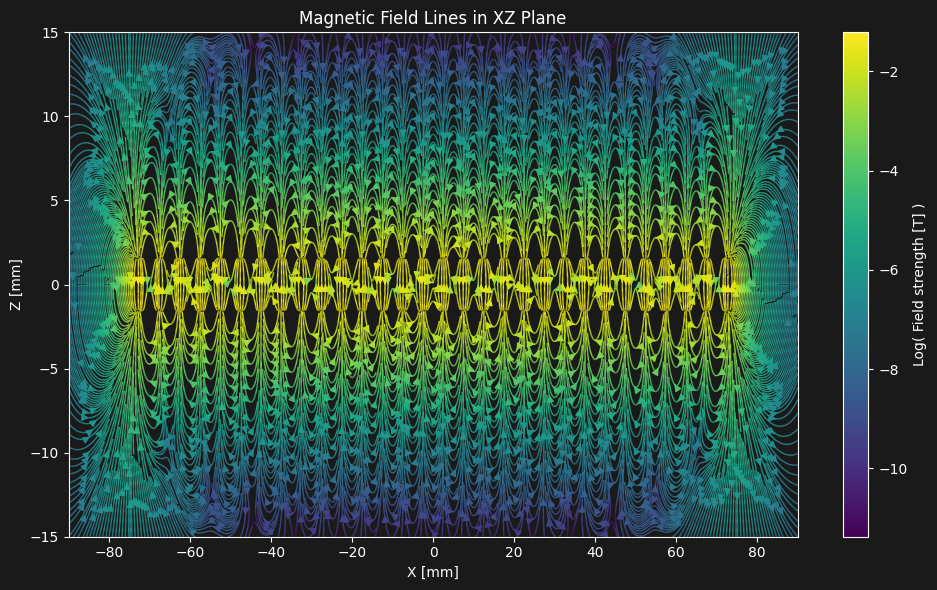

In [ ]:
plot_plano(coleccion1, imanes1, xlim=[-90, 90], zlim=[-15, 15], y_plano=2.5)

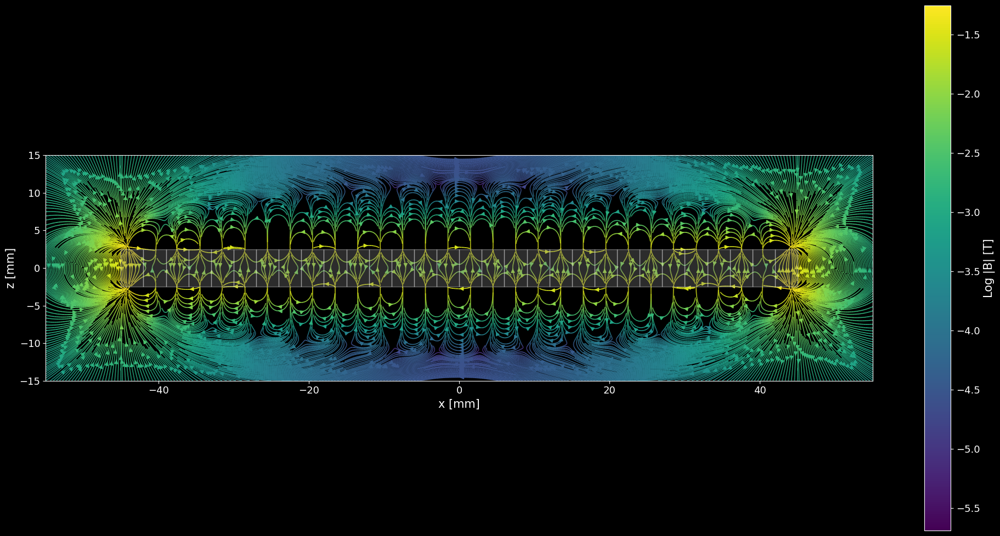

In [ ]:
num_magnets = 30
spacing = 3             # mm between magnet centers
radius = 1.5            # mm
height = 5               # mm
mag_strength = 900e3    # A/m
show_3d_viewer = False  # show 3d viewer with simulation scene
plot_range = [spacing * num_magnets + 20, 30]

#INSTANCIAMOS LA FILA DE IMANES

imanes = []
posiciones = []
for i in range(num_magnets):
    signo = 1 if i % 2 == 0 else -1
    x = (i - (num_magnets - 1) / 2) * spacing
    m = magpy.magnet.Cylinder(
        magnetization=(0, 0, signo * mag_strength),
        dimension=(2*radius, height),
        position=(x, 0, 0),
    )
    imanes.append(m)
    posiciones.append(x)

coleccion = magpy.Collection(imanes)

if show_3d_viewer:
    coleccion.show()

# GRILLA PARA VER DONDE MEDIMOS EL CAMPO (plano y=2.5, fuera del cuerpo del imán)

x_range, z_range = plot_range
xs = np.linspace(-x_range/2, x_range/2, 1000)
zs = np.linspace(-z_range/2, z_range/2, 600)
grid = np.array([[(x, 3, z) for x in xs] for z in zs])
X, _, Z = np.moveaxis(grid, 2, 0)

#OBTENEMOS EL CAMPO

B = coleccion.getB(grid)
Bx, _, Bz = np.moveaxis(B, 2, 0)
log10_normB = np.log10(np.linalg.norm(B, axis=2))


plt.style.use('dark_background')
plt.rcParams.update({'font.size': 14})

fig, ax = plt.subplots(figsize=(20, 10))

splt = ax.streamplot(
    X, Z, Bx, Bz,
    density=18,
    color=log10_normB,
    linewidth=1.2,
    cmap="viridis",
)

cb = fig.colorbar(splt.lines, ax=ax, label="Log |B| [T]")
cb.ax.tick_params(labelsize=13)
cb.set_label("Log |B| [T]", fontsize=15)

#imanes: celda semitransparente + borde
for x in posiciones:
    rect = patches.Rectangle(
        (x - radius, -height/2), 2*radius, height,
        facecolor="gray", alpha=0.35,
        edgecolor="white", lw=1, zorder=3,
    )
    ax.add_patch(rect)

ax.set(xlabel="x [mm]", ylabel="z [mm]", aspect=1)
ax.tick_params(labelsize=13)
ax.xaxis.label.set_size(15)
ax.yaxis.label.set_size(15)

plt.tight_layout()
plt.show()

ZOOM DE AMBAS CONFIGURACIONES

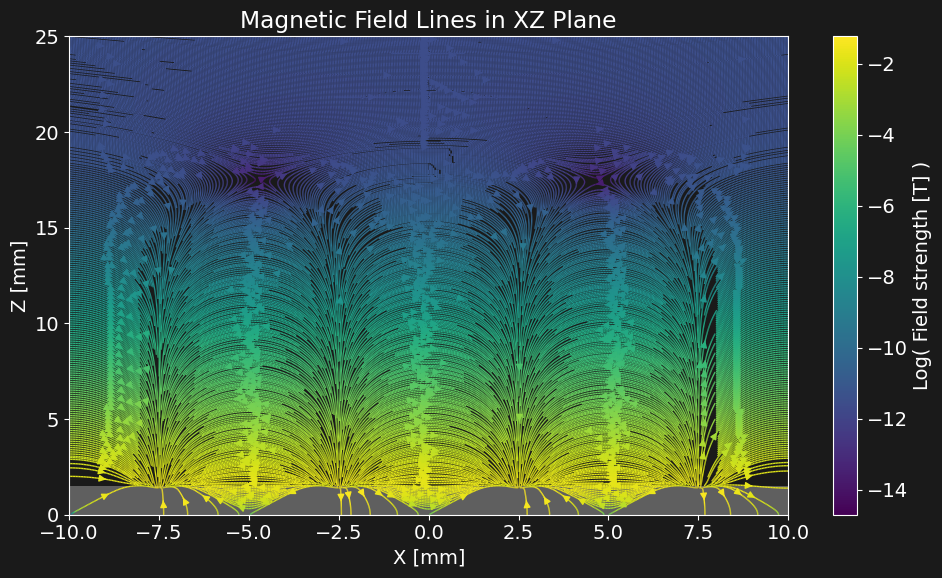

In [ ]:
#Definimos una grilla menos densa enfocada solo en la región del zoom
x_min, x_max = -10, 10
z_min, z_max = 0, 25

plot_plano(coleccion1, imanes1, xlim=[x_min, x_max], zlim=[z_min, z_max], y_plano=3)

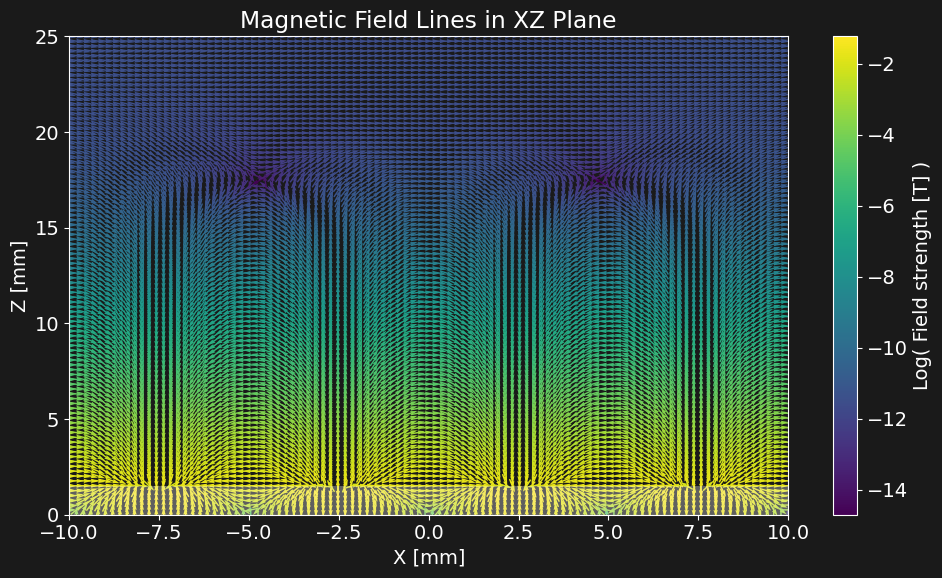

In [ ]:
#Definimos una grilla menos densa enfocada solo en la región del zoom
x_min, x_max = -10, 10
z_min, z_max = 0, 25

#IMAN 1

plot_plano(coleccion1, imanes1, xlim=[x_min, x_max], zlim=[z_min, z_max], y_plano=3, plot_type='field_direction', zoom=True)

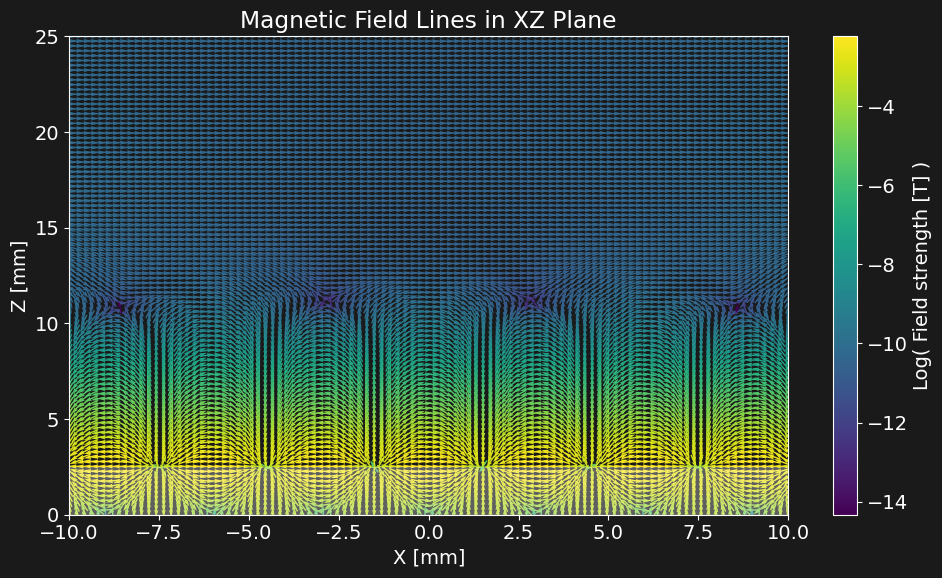

In [ ]:
#Definimos una grilla menos densa enfocada solo en la región del zoom
x_min, x_max = -10, 10
z_min, z_max = 0, 25

#IMAN 2

plot_plano(coleccion2, imanes2, xlim=[x_min, x_max], zlim=[z_min, z_max], y_plano=2, plot_type='field_direction', zoom=True) #Y = 2 PARA DEJAR AIRGAP DE 0.5MM

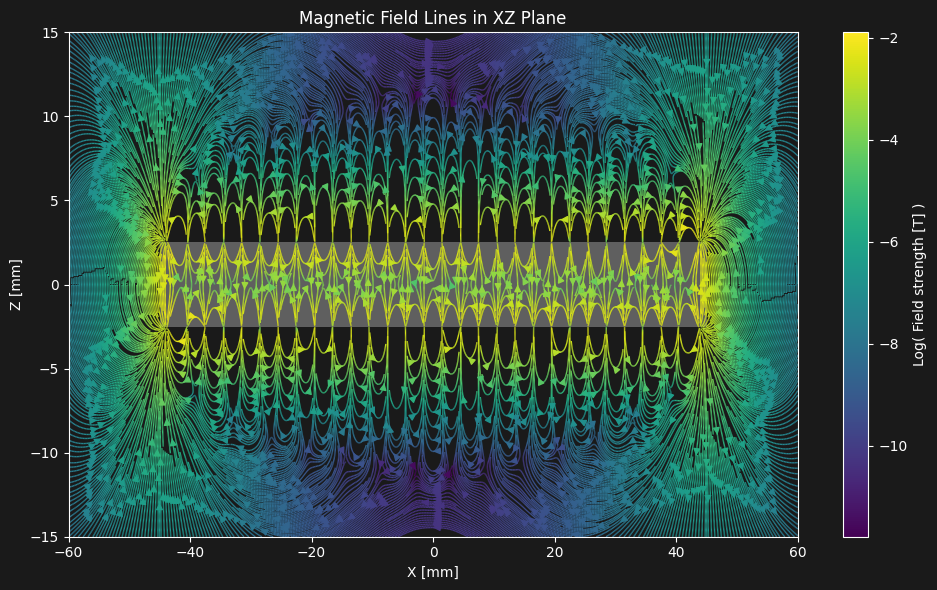

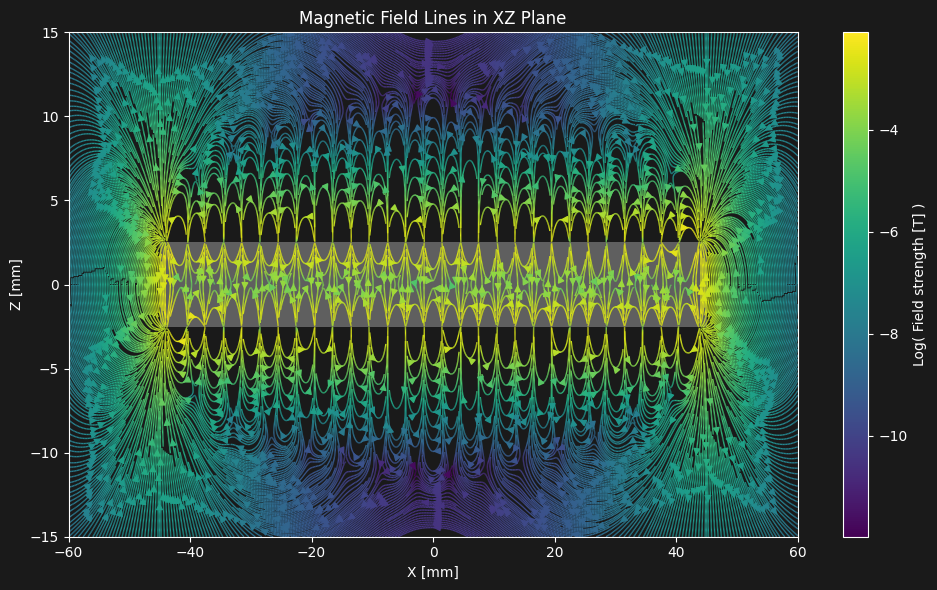

In [ ]:
plot_plano(coleccion3, imanes3, xlim=[-60, 60], zlim=[-15, 15], y_plano=2)
plot_plano(coleccion4, imanes4, xlim=[-60, 60], zlim=[-15, 15], y_plano=2)

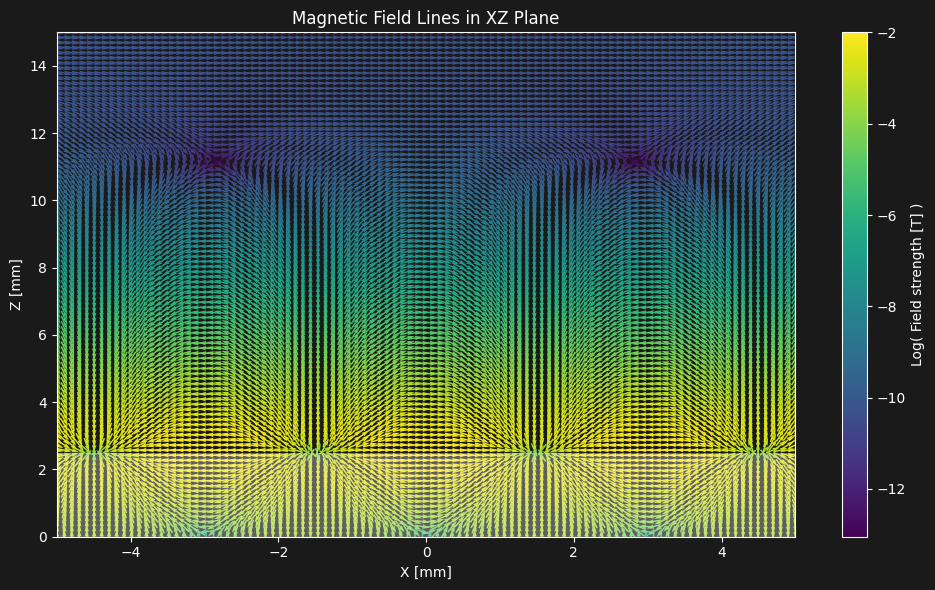

In [ ]:
#Definimos una grilla menos densa enfocada solo en la región del zoom
x_min, x_max = -5, 5
z_min, z_max = 0, 15

#IMAN 1

plot_plano(coleccion3, imanes3, xlim=[x_min, x_max], zlim=[z_min, z_max], y_plano=2, plot_type='field_direction', zoom=True)

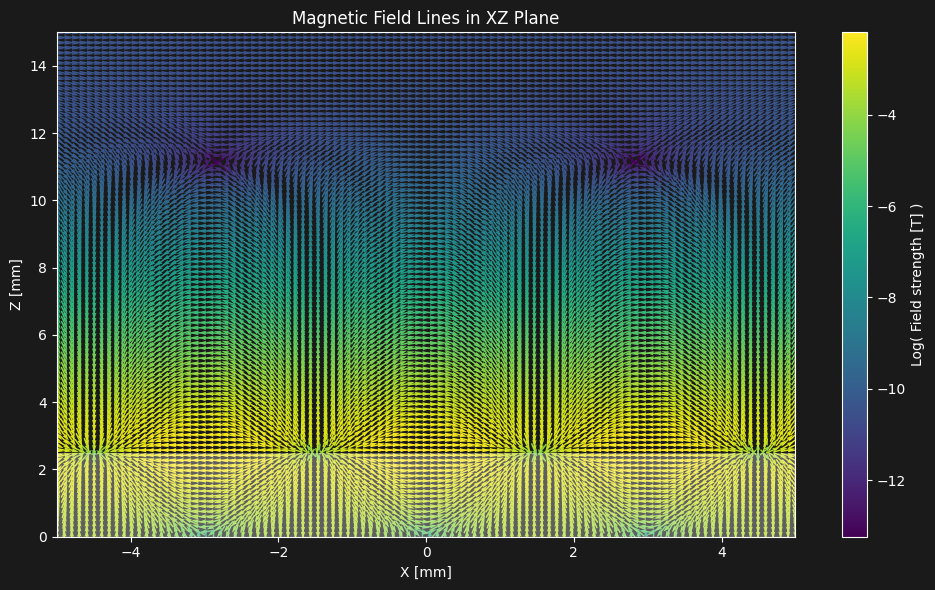

In [ ]:
#Definimos una grilla menos densa enfocada solo en la región del zoom
x_min, x_max = -5, 5
z_min, z_max = 0, 15

#IMAN 1

plot_plano(coleccion4, imanes4, xlim=[x_min, x_max], zlim=[z_min, z_max], y_plano=2, plot_type='field_direction', zoom=True)

##GRAFICOS DE FIELD ANGLE + LISSAJOUS

In [ ]:
#PARAMETROS PARA BARRER

xlim1=(4.5, 15)
zlim1=(-15, 15)
alturas_z=[2,2.5,3,3.5,4,4.5,6,7,8,]
altura_lissajous= 4
n_planos=1
x_range_r21 = (6,14)




=== y_plano = 3.00 mm ===


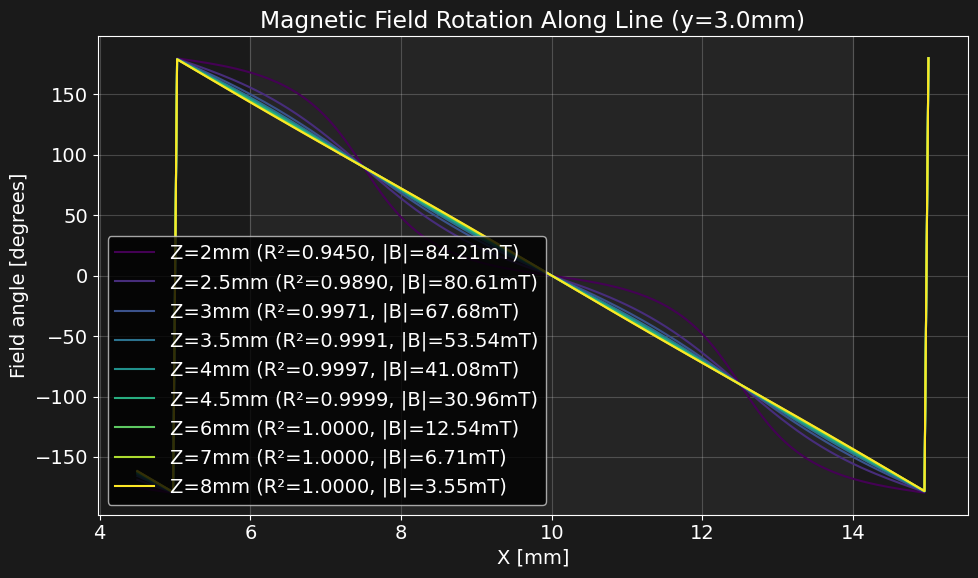

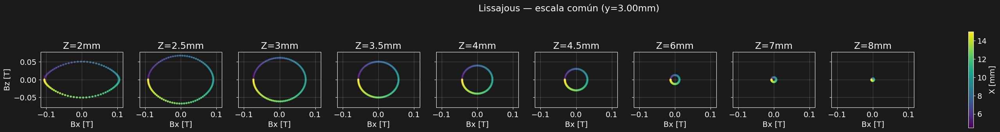

{np.float64(3.0): {2: {'r2': np.float64(0.9450347041142904),
   'amplitud_mT': np.float64(84.20998345833283)},
  2.5: {'r2': np.float64(0.9890484192639775),
   'amplitud_mT': np.float64(80.60963826793342)},
  3: {'r2': np.float64(0.9970686243867828),
   'amplitud_mT': np.float64(67.67661127969625)},
  3.5: {'r2': np.float64(0.999059003893058),
   'amplitud_mT': np.float64(53.54281017431166)},
  4: {'r2': np.float64(0.9996694171378893),
   'amplitud_mT': np.float64(41.082675352560436)},
  4.5: {'r2': np.float64(0.9998848136005766),
   'amplitud_mT': np.float64(30.96361743858922)},
  6: {'r2': np.float64(0.9999999709092314),
   'amplitud_mT': np.float64(12.542493104569713)},
  7: {'r2': np.float64(0.9999900968276005),
   'amplitud_mT': np.float64(6.705090221385708)},
  8: {'r2': np.float64(0.9999757668751584),
   'amplitud_mT': np.float64(3.5504254625192053)}}}

In [ ]:
#FIELD ANGLE + LISSAJOUS IMAN 1


barrer_y_plano(coleccion1, imanes1, xlim= xlim1 , zlim=zlim1, alturas_z= alturas_z, altura_lissajous=altura_lissajous, n_planos=n_planos, x_range_r2=x_range_r21)

In [ ]:
#PARAMETROS PARA BARRER IMAN 2

xlim2=(8.5, 15)
zlim2=(-15, 15)
alturas_z=[2,2.5,3,3.5,4,4.5,6,7,8,]
altura_lissajous= 4
n_planos=1
x_range_r22 = (9.5,14.5)


=== y_plano = 2.00 mm ===


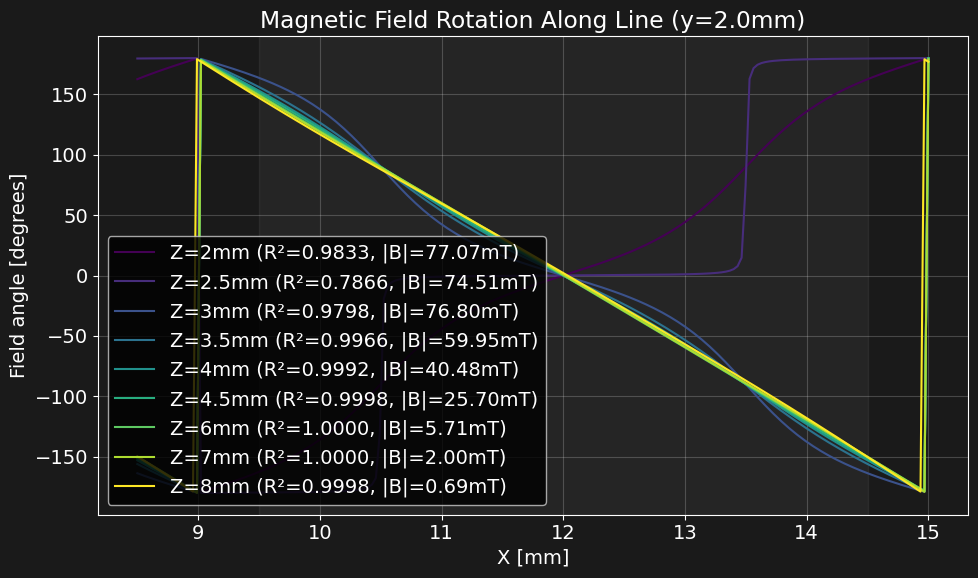

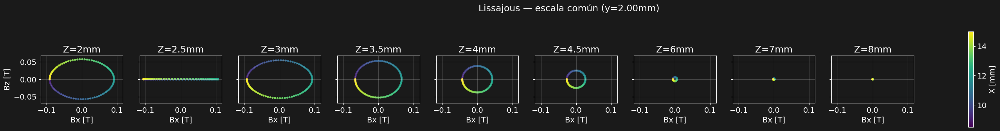

{np.float64(2.0): {2: {'r2': np.float64(0.9833147351252095),
   'amplitud_mT': np.float64(77.07082063271221)},
  2.5: {'r2': np.float64(0.7865536804626589),
   'amplitud_mT': np.float64(74.51011907049809)},
  3: {'r2': np.float64(0.9797627130169542),
   'amplitud_mT': np.float64(76.79791873305967)},
  3.5: {'r2': np.float64(0.996594524024641),
   'amplitud_mT': np.float64(59.94815873309852)},
  4: {'r2': np.float64(0.9991916280624563),
   'amplitud_mT': np.float64(40.483386986824875)},
  4.5: {'r2': np.float64(0.999776737695679),
   'amplitud_mT': np.float64(25.701598651191926)},
  6: {'r2': np.float64(0.9999949702252177),
   'amplitud_mT': np.float64(5.710552098360398)},
  7: {'r2': np.float64(0.9999707276446276),
   'amplitud_mT': np.float64(1.9973658185062542)},
  8: {'r2': np.float64(0.9997714916477843),
   'amplitud_mT': np.float64(0.6870688727874606)}}}

In [ ]:
#FIELD ANGLE + LISAJJOUS IMAN 2

barrer_y_plano(coleccion2, imanes2, xlim= xlim2 , zlim=zlim2, alturas_z= alturas_z, altura_lissajous=altura_lissajous, n_planos=n_planos, x_range_r2=x_range_r22)

In [ ]:
#PARAMETROS PARA BARRER IMAN 3

xlim3=(8.5, 15.5)
zlim3=(-15, 18)
alturas_z=[4.05]
altura_lissajous= 4
n_planos=1
x_range_r23 = (9.5,14.5)


=== y_plano = 1.59 mm ===

=== y_plano = 1.59 mm ===


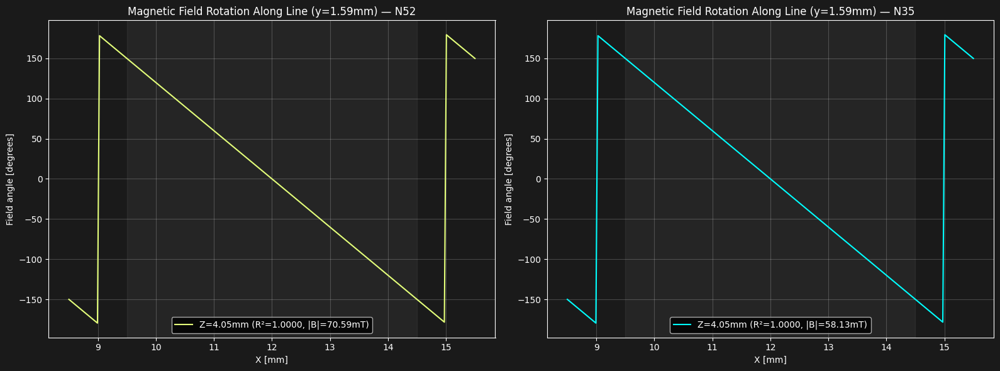

In [ ]:
#FIELD ANGLE + LISAJJOUS IMAN 3

plt.style.use('dark_background')
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.set_facecolor((0.1, 0.1, 0.1))

barrer_y_plano(coleccion3, imanes3, xlim=xlim3, zlim=zlim3, alturas_z=alturas_z, altura_lissajous=altura_lissajous,
               n_planos=1, x_range_r2=x_range_r23, cmap="Wistia", airgap=0.09, ax=axes[0])
axes[0].set_title(axes[0].get_title() + " — N52")
barrer_y_plano(coleccion4, imanes4, xlim=xlim3, zlim=zlim3, alturas_z=alturas_z, altura_lissajous=altura_lissajous,
               n_planos=1, x_range_r2=x_range_r23, cmap="cool", airgap=0.09, ax=axes[1])
axes[1].set_title(axes[1].get_title() + " — N35")

plt.tight_layout()
plt.show()

In [ ]:
#PARAMETROS PARA BARRER IMAN 4

xlim3=(8.5, 15.5)
zlim3=(-15, 18)
alturas_z=[4.05]
altura_lissajous= 4
n_planos=1
x_range_r23 = (9.5,14.5)


=== y_plano = 1.59 mm ===


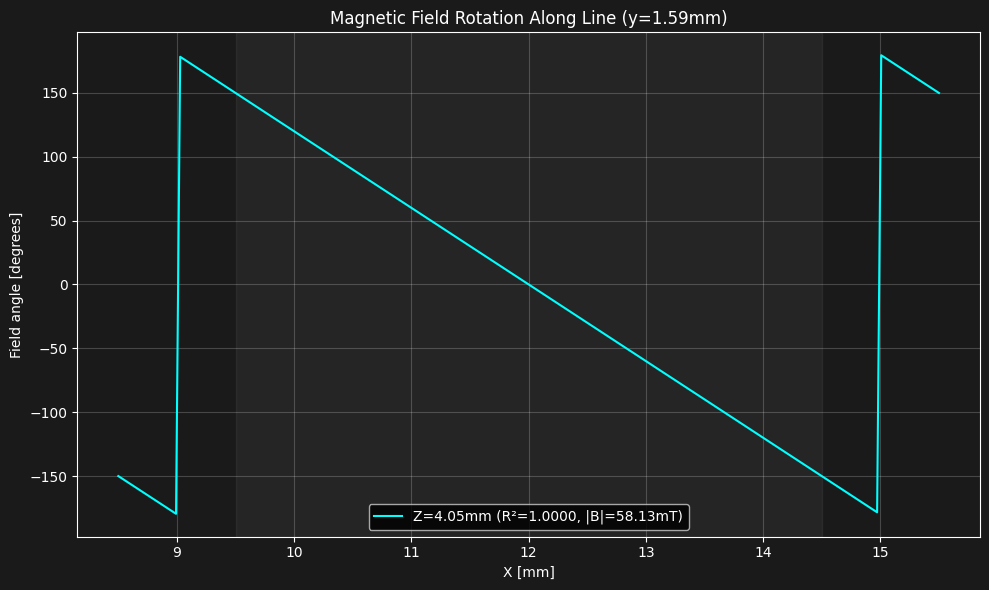

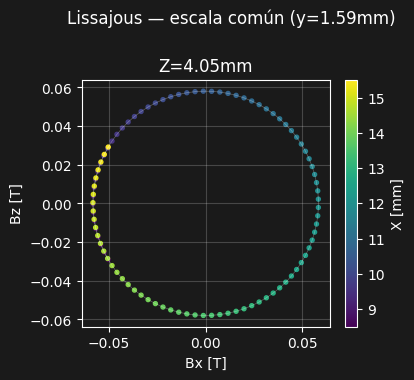

{np.float64(1.59): {4.05: {'r2': np.float64(0.9999998859656176),
   'amplitud_mT': np.float64(58.13101526794442)}}}

In [ ]:
#FIELD ANGLE + LISAJJOUS IMAN4

barrer_y_plano(coleccion4, imanes4, xlim= xlim3 , zlim=zlim3, alturas_z= alturas_z, altura_lissajous=altura_lissajous, n_planos=n_planos, x_range_r2=x_range_r23,cmap='cool', airgap = 0.09)

##OPTIMIZACION POR VELOCIDAD ANGULAR

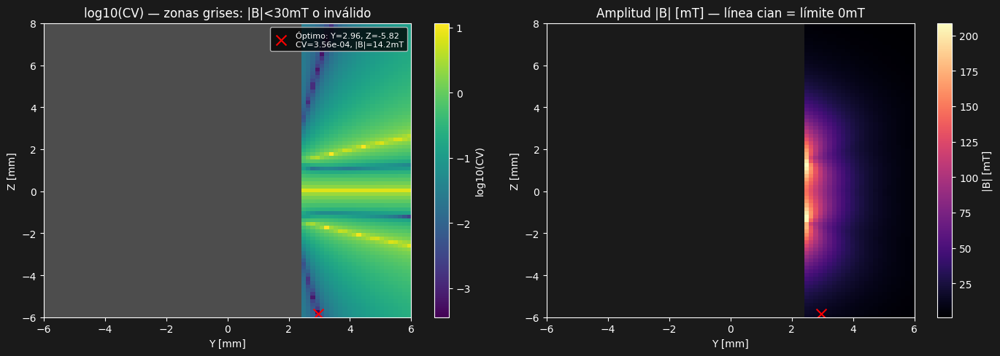

Óptimo: Y=2.96mm, Z=-5.82mm, CV=3.56e-04, |B|=14.2mT


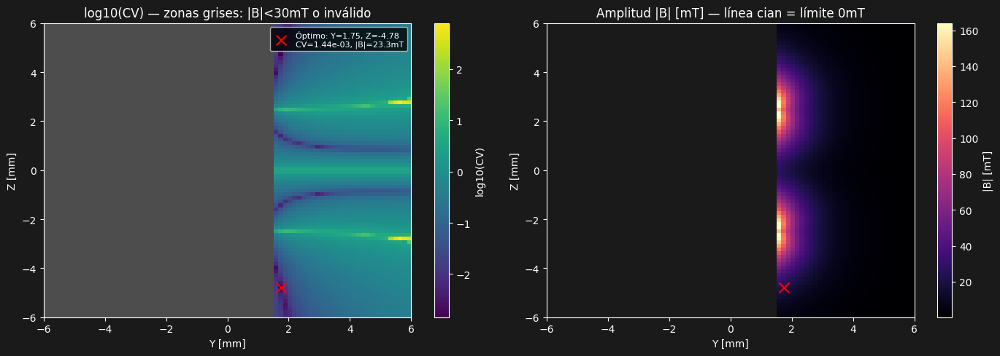

Óptimo: Y=1.75mm, Z=-4.78mm, CV=1.44e-03, |B|=23.3mT


In [ ]:
radio_iman1 = imanes1[0].dimension[0] / 2
radio_iman2 = imanes2[0].dimension[0] / 2

y_vals1 = np.linspace(-6, 6.0, 80)
z_vals1 = np.linspace(-6, 8.0, 80)

y_vals2 = np.linspace(-6, 6.0, 80)
z_vals2 = np.linspace(-6, 6.0, 80)

cv_map1, amp_map1, (y_opt1, z_opt1) = mapa_uniformidad(
    coleccion=coleccion1,
    xlim=(0, 17.5),
    y_vals=y_vals1,
    z_vals=z_vals1,
    x_range=x_range_r21,
    y_min_fisico=radio_iman1,
    amplitud_min_mT=0,
)

cv_map2, amp_map2, (y_opt2, z_opt2) = mapa_uniformidad(
    coleccion=coleccion2,
    xlim=(0, 17.5),
    y_vals=y_vals2,
    z_vals=z_vals2,
    x_range=x_range_r22,
    y_min_fisico=radio_iman2,
    amplitud_min_mT=0,
)


##CORRECCION DE LAS FUNCIONES

In [ ]:
def evaluar_punto(coleccion, xlim, y_plano, z_plano, x_range=None, resolucion=500):
    x, dtheta_dx = velocidad_angular(coleccion, xlim, y_plano, z_plano, resolucion)

    Y = np.full_like(x, y_plano)
    Z = np.full_like(x, z_plano)
    posiciones = np.stack([x, Y, Z], axis=-1)
    B = coleccion.getB(posiciones)
    amplitud_mT = np.mean(np.sqrt(B[:,0]**2 + B[:,2]**2)) * 1000

    if x_range is not None:
        mask = (x >= x_range[0]) & (x <= x_range[1])
        dtheta_dx = dtheta_dx[mask]

    cv = np.std(dtheta_dx) / np.abs(np.mean(dtheta_dx))
    return cv, amplitud_mT


def mapa_uniformidad(coleccion, xlim, y_vals, z_vals, x_range=None,
                      y_min_fisico=None, amplitud_min_mT=30):

    cv_map = np.full((len(z_vals), len(y_vals)), np.nan)
    amp_map = np.full((len(z_vals), len(y_vals)), np.nan)

    for i, z in enumerate(z_vals):
        for j, y in enumerate(y_vals):
            if y_min_fisico is not None and abs(y) < y_min_fisico:
                continue  # dentro del imán (por cualquiera de los dos lados), inválido

            cv, amp = evaluar_punto(coleccion, xlim, y_plano=y, z_plano=z, x_range=x_range)
            amp_map[i, j] = amp

            if amp < amplitud_min_mT:
                continue

            cv_map[i, j] = cv

    if np.all(np.isnan(cv_map)):
        raise ValueError("Ningún punto cumple los límites físicos y de amplitud mínima")

    i_min, j_min = np.unravel_index(np.nanargmin(cv_map), cv_map.shape)
    z_optimo, y_optimo = z_vals[i_min], y_vals[j_min]
    cv_optimo = cv_map[i_min, j_min]
    amp_optimo = amp_map[i_min, j_min]

    plt.style.use('dark_background')
    fig, axs = plt.subplots(1, 2, figsize=(14, 5))

    im0 = axs[0].imshow(np.log10(cv_map), origin='lower', aspect='auto', cmap='viridis',
                         extent=[y_vals.min(), y_vals.max(), z_vals.min(), z_vals.max()])
    axs[0].scatter([y_optimo], [z_optimo], color='red', marker='x', s=100,
                   label=f"Óptimo: Y={y_optimo:.2f}, Z={z_optimo:.2f}\nCV={cv_optimo:.2e}, |B|={amp_optimo:.1f}mT")
    axs[0].set_xlabel("Y [mm]"); axs[0].set_ylabel("Z [mm]")
    axs[0].set_title("log10(CV) — zonas grises: dentro del imán o |B| insuficiente")
    axs[0].legend(loc='upper right', fontsize=8)
    axs[0].set_facecolor((0.3, 0.3, 0.3))
    plt.colorbar(im0, ax=axs[0], label='log10(CV)')

    im1 = axs[1].imshow(amp_map, origin='lower', aspect='auto', cmap='magma',
                         extent=[y_vals.min(), y_vals.max(), z_vals.min(), z_vals.max()])
    if amplitud_min_mT > 0:
        axs[1].contour(y_vals, z_vals, amp_map, levels=[amplitud_min_mT], colors='cyan', linewidths=2)
    axs[1].scatter([y_optimo], [z_optimo], color='red', marker='x', s=100)
    axs[1].set_xlabel("Y [mm]"); axs[1].set_ylabel("Z [mm]")
    axs[1].set_title(f"Amplitud |B| [mT] — línea cian = límite {amplitud_min_mT}mT")
    axs[1].set_facecolor((0.1, 0.1, 0.1))
    plt.colorbar(im1, ax=axs[1], label='|B| [mT]')

    fig.set_facecolor((0.1, 0.1, 0.1))
    plt.tight_layout()
    plt.show()

    print(f"Óptimo: Y={y_optimo:.2f}mm, Z={z_optimo:.2f}mm, CV={cv_optimo:.2e}, |B|={amp_optimo:.1f}mT")

    return cv_map, amp_map, (y_optimo, z_optimo)

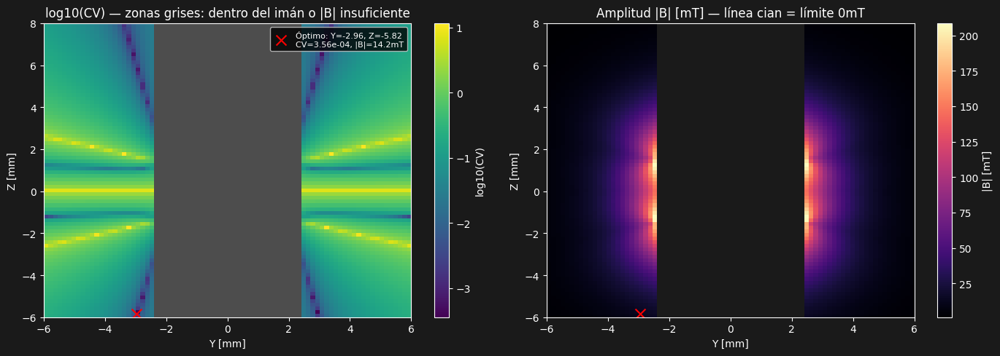

Óptimo: Y=-2.96mm, Z=-5.82mm, CV=3.56e-04, |B|=14.2mT


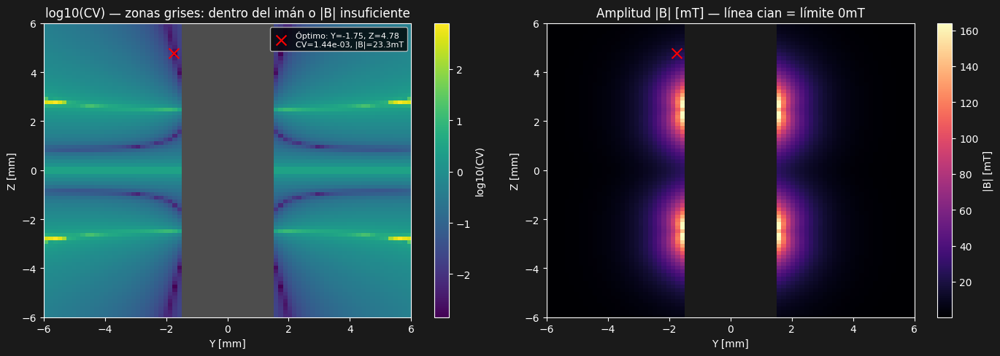

Óptimo: Y=-1.75mm, Z=4.78mm, CV=1.44e-03, |B|=23.3mT


In [ ]:
radio_iman1 = imanes1[0].dimension[0] / 2
radio_iman2 = imanes2[0].dimension[0] / 2

y_vals1 = np.linspace(-6, 6.0, 80)
z_vals1 = np.linspace(-6, 8.0, 80)

y_vals2 = np.linspace(-6, 6.0, 80)
z_vals2 = np.linspace(-6, 6.0, 80)

cv_map1, amp_map1, (y_opt1, z_opt1) = mapa_uniformidad(
    coleccion=coleccion1,
    xlim=(0, 17.5),
    y_vals=y_vals1,
    z_vals=z_vals1,
    x_range=x_range_r21,
    y_min_fisico=radio_iman1,
    amplitud_min_mT=0,
)

cv_map2, amp_map2, (y_opt2, z_opt2) = mapa_uniformidad(
    coleccion=coleccion2,
    xlim=(0, 17.5),
    y_vals=y_vals2,
    z_vals=z_vals2,
    x_range=x_range_r22,
    y_min_fisico=radio_iman2,
    amplitud_min_mT=0,
)


##CORRECION DE LAS FUNCIONES 2

In [ ]:
def evaluar_punto(coleccion, xlim, y_plano, z_plano, x_range=None, resolucion=500):
    x, dtheta_dx = velocidad_angular(coleccion, xlim, y_plano, z_plano, resolucion)

    Y = np.full_like(x, y_plano)
    Z = np.full_like(x, z_plano)
    posiciones = np.stack([x, Y, Z], axis=-1)
    B = coleccion.getB(posiciones)
    amplitud_mT = np.mean(np.sqrt(B[:,0]**2 + B[:,2]**2)) * 1000

    if x_range is not None:
        mask = (x >= x_range[0]) & (x <= x_range[1])
        dtheta_dx = dtheta_dx[mask]

    cv = np.std(dtheta_dx) / np.abs(np.mean(dtheta_dx))
    return cv, amplitud_mT

def mapa_uniformidad(coleccion, xlim, y_vals, z_vals, x_range=None,
                      radio_iman=None, altura_iman=None, z_centro_iman=0,
                      amplitud_min_mT=30, material=None):

    cv_map = np.full((len(z_vals), len(y_vals)), np.nan)
    amp_map = np.full((len(z_vals), len(y_vals)), np.nan)

    for i, z in enumerate(z_vals):
        for j, y in enumerate(y_vals):

            # el punto está DENTRO del volumen del imán solo si se cumplen
            # simultáneamente la condición radial (Y) y la de altura (Z)
            dentro_del_iman = False
            if radio_iman is not None and altura_iman is not None:
                dentro_del_iman = (abs(y) < radio_iman) and (abs(z - z_centro_iman) < altura_iman / 2)

            if dentro_del_iman:
                continue  # inválido de verdad: adentro del material

            cv, amp = evaluar_punto(coleccion, xlim, y_plano=y, z_plano=z, x_range=x_range)
            amp_map[i, j] = amp

            if amp < amplitud_min_mT:
                continue

            cv_map[i, j] = cv

    if np.all(np.isnan(cv_map)):
        raise ValueError("Ningún punto cumple los límites físicos y de amplitud mínima")

    i_min, j_min = np.unravel_index(np.nanargmin(cv_map), cv_map.shape)
    z_optimo, y_optimo = z_vals[i_min], y_vals[j_min]
    cv_optimo = cv_map[i_min, j_min]
    amp_optimo = amp_map[i_min, j_min]

    plt.style.use('dark_background')
    fig, axs = plt.subplots(1, 2, figsize=(14, 5))

    im0 = axs[0].imshow(np.log10(cv_map), origin='lower', aspect='auto', cmap='viridis',
                         extent=[y_vals.min(), y_vals.max(), z_vals.min(), z_vals.max()])
    axs[0].scatter([y_optimo], [z_optimo], color='red', marker='x', s=100,
                   label=f"Óptimo: Y={y_optimo:.2f}, Z={z_optimo:.2f}\nCV={cv_optimo:.2e}, |B|={amp_optimo:.1f}mT")
    axs[0].set_xlabel("Y [mm]"); axs[0].set_ylabel("Z [mm]")
    axs[0].set_title("log10(CV) — gris: dentro del imán o |B| insuficiente")
    axs[0].legend(loc='upper right', fontsize=8)
    axs[0].set_facecolor((0.3, 0.3, 0.3))
    plt.colorbar(im0, ax=axs[0], label='log10(CV)')

    im1 = axs[1].imshow(amp_map, origin='lower', aspect='auto', cmap='magma',
                         extent=[y_vals.min(), y_vals.max(), z_vals.min(), z_vals.max()])
    if amplitud_min_mT > 0:
        axs[1].contour(y_vals, z_vals, amp_map, levels=[amplitud_min_mT], colors='cyan', linewidths=2)
    axs[1].scatter([y_optimo], [z_optimo], color='red', marker='x', s=100)
    axs[1].set_xlabel("Y [mm]"); axs[1].set_ylabel("Z [mm]")
    axs[1].set_title(f"Amplitud |B| [mT] — línea cian = límite {amplitud_min_mT}mT")
    axs[1].set_facecolor((0.1, 0.1, 0.1))
    plt.colorbar(im1, ax=axs[1], label='|B| [mT]')

    fig.set_facecolor((0.1, 0.1, 0.1))
    if material is not None:
        fig.suptitle(f"Configuración {material}", color='white', fontsize=14)
    plt.tight_layout()
    plt.show()

    print(f"Óptimo: Y={y_optimo:.2f}mm, Z={z_optimo:.2f}mm, CV={cv_optimo:.2e}, |B|={amp_optimo:.1f}mT")

    return cv_map, amp_map, (y_optimo, z_optimo)

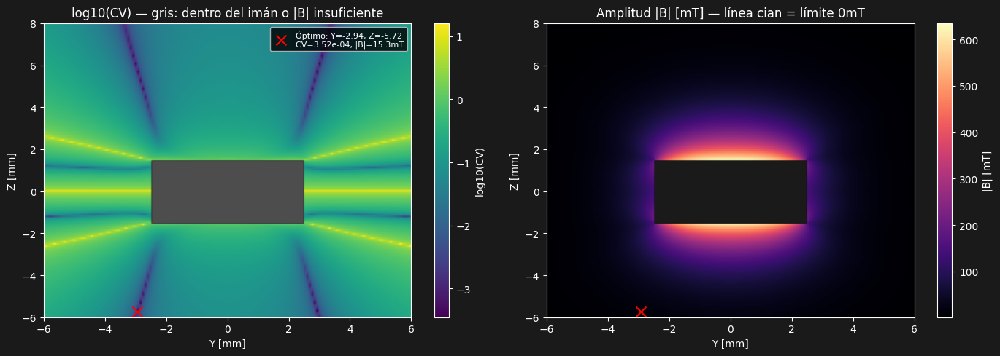

Óptimo: Y=-2.94mm, Z=-5.72mm, CV=3.52e-04, |B|=15.3mT


In [ ]:
radio_iman1 = imanes1[0].dimension[0] / 2
altura_iman1 = imanes1[0].dimension[1]
z_centro1 = imanes1[0].position[2]  # normalmente 0, pero lo tomo del objeto en vez de asumirlo

y_vals1 = np.linspace(-6, 6.0, 150)
z_vals1 = np.linspace(-6, 8.0, 150)

cv_map1, amp_map1, (y_opt1, z_opt1) = mapa_uniformidad(
    coleccion=coleccion1,
    xlim=(0, 17.5),
    y_vals=y_vals1,
    z_vals=z_vals1,
    x_range=x_range_r21,
    radio_iman=radio_iman1,
    altura_iman=altura_iman1,
    z_centro_iman=z_centro1,
    amplitud_min_mT=0,   # ojo: volví a ponerlo en 30, no en 0
)

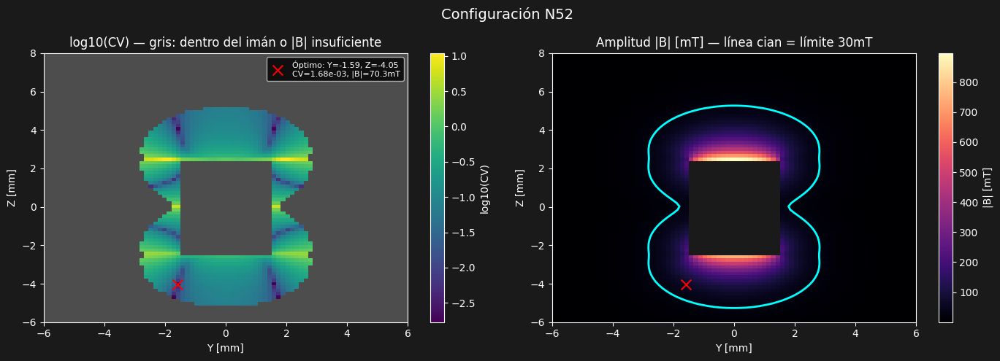

Óptimo: Y=-1.59mm, Z=-4.05mm, CV=1.68e-03, |B|=70.3mT


In [ ]:
# ==========================================
# CÁLCULO DE MAPA PARA CONFIGURACIÓN 3 (N52)
# ==========================================
radio_iman3 = imanes3[0].dimension[0] / 2
altura_iman3 = imanes3[0].dimension[1]
z_centro3 = imanes3[0].position[2]

#PARAMETROS PARA BARRER IMAN 2
x_range_r23 = (9.5,14.5)

y_vals3 = np.linspace(-6, 6.0, 80)
z_vals3 = np.linspace(-6, 8.0, 80)

cv_map3, amp_map3, (y_opt3, z_opt3) = mapa_uniformidad(
    coleccion=coleccion3,
    xlim=(0, 17.5),
    y_vals=y_vals3,
    z_vals=z_vals3,
    x_range=x_range_r23,
    radio_iman=radio_iman3,
    altura_iman=altura_iman3,
    z_centro_iman=z_centro3,
    amplitud_min_mT=30,
    material="N52",
)

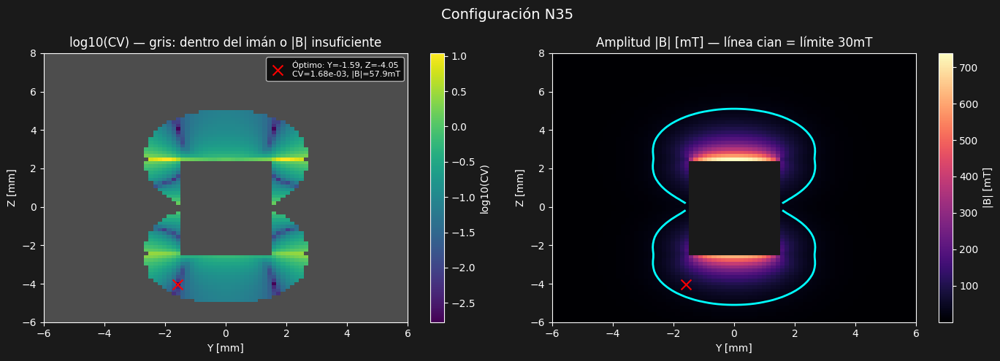

Óptimo: Y=-1.59mm, Z=-4.05mm, CV=1.68e-03, |B|=57.9mT


In [ ]:
# ==========================================
# CÁLCULO DE MAPA PARA CONFIGURACIÓN 4 (N35)
# ==========================================
radio_iman4 = imanes4[0].dimension[0] / 2
altura_iman4 = imanes4[0].dimension[1]
z_centro4 = imanes4[0].position[2]

#PARAMETROS PARA BARRER IMAN 2
x_range_r24 = (9.5,14.5)

y_vals4 = np.linspace(-6, 6.0, 80)
z_vals4 = np.linspace(-6, 8.0, 80)

cv_map4, amp_map4, (y_opt4, z_opt4) = mapa_uniformidad(
    coleccion=coleccion4,
    xlim=(0, 17.5),
    y_vals=y_vals4,
    z_vals=z_vals4,
    x_range=x_range_r24,  # <-- Asegúrate de definir x_range_r44 previamente
    radio_iman=radio_iman4,
    altura_iman=altura_iman4,
    z_centro_iman=z_centro4,
    amplitud_min_mT=30,
    material="N35",
)